# Practical 6: Faster R-CNN for Object Detection (PyTorch)

**Dataset:** Penn-Fudan Pedestrian Database (170 images, 345 annotated pedestrians)
**Task:** Detect pedestrians (classes = background + person)
**Model:** Faster R-CNN, ResNet-50 + FPN backbone, pretrained on COCO, fine-tuned on Penn-Fudan

Set the Colab runtime to GPU first: *Runtime > Change runtime type > T4 GPU*.

## 1. Setup

In [1]:
!pip install -q torchmetrics pycocotools

In [2]:
import os, time, random, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
import torchvision.transforms.functional as TF
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# fixed seed so results can be reproduced
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (training will be slow!)")

PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
Device: cuda | Tesla T4


## 2. Dataset

Penn-Fudan has images of pedestrians and, for each image, a mask where every pedestrian has its own id (1, 2, 3, ...).
We turn each mask into a tight bounding box `[xmin, ymin, xmax, ymax]`. Label `0` is reserved for background, so `1 = person`.

In [3]:
url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
if not os.path.exists("PennFudanPed"):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, "PennFudanPed.zip")
    with zipfile.ZipFile("PennFudanPed.zip") as z:
        z.extractall(".")
print("Images found:", len(os.listdir("PennFudanPed/PNGImages")))

Images found: 170


In [4]:
CLASS_NAMES = ["__background__", "person"]
NUM_CLASSES = len(CLASS_NAMES)   # background + person = 2

class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root, train=False):
        self.root = root
        self.train = train
        self.imgs = sorted(os.listdir(os.path.join(root, "PNGImages")))
        self.masks = sorted(os.listdir(os.path.join(root, "PedMasks")))

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.root, "PNGImages", self.imgs[idx])).convert("RGB")
        mask = np.array(Image.open(os.path.join(self.root, "PedMasks", self.masks[idx])))

        # every pedestrian has a different id in the mask (0 = background)
        obj_ids = np.unique(mask)[1:]
        boxes = []
        for obj_id in obj_ids:
            ys, xs = np.where(mask == obj_id)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.ones((len(boxes),), dtype=torch.int64)   # only one class: person

        img = TF.to_tensor(img)

        # simple augmentation: random horizontal flip (training only)
        if self.train and random.random() < 0.5:
            img = img.flip(-1)
            w = img.shape[-1]
            boxes[:, [0, 2]] = w - boxes[:, [2, 0]]

        target = {"boxes": boxes, "labels": labels}
        return img, target

    def __len__(self):
        return len(self.imgs)

def collate_fn(batch):
    # images have different sizes / number of boxes, so we keep them as tuples
    return tuple(zip(*batch))

### Train / test split (120 train, 50 test, fixed seed)

In [5]:
full_train = PennFudanDataset("PennFudanPed", train=True)    # with flip augmentation
full_test  = PennFudanDataset("PennFudanPed", train=False)   # no augmentation

indices = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, test_idx = indices[:-50], indices[-50:]

train_ds = torch.utils.data.Subset(full_train, train_idx)
test_ds  = torch.utils.data.Subset(full_test,  test_idx)
print("Train images:", len(train_ds), "| Test images:", len(test_ds))

BATCH_SIZE = 4
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                           num_workers=2, collate_fn=collate_fn)
test_loader  = torch.utils.data.DataLoader(test_ds, batch_size=2, shuffle=False,
                                           num_workers=2, collate_fn=collate_fn)

Train images: 120 | Test images: 50


### Annotation format and ground-truth samples

Image tensor shape : (3, 536, 559)
Target keys        : ['boxes', 'labels']
boxes  [N,4] float : tensor([[159., 181., 302., 431.],
        [419., 170., 535., 486.]])
labels [N]   int64 : tensor([1, 1])


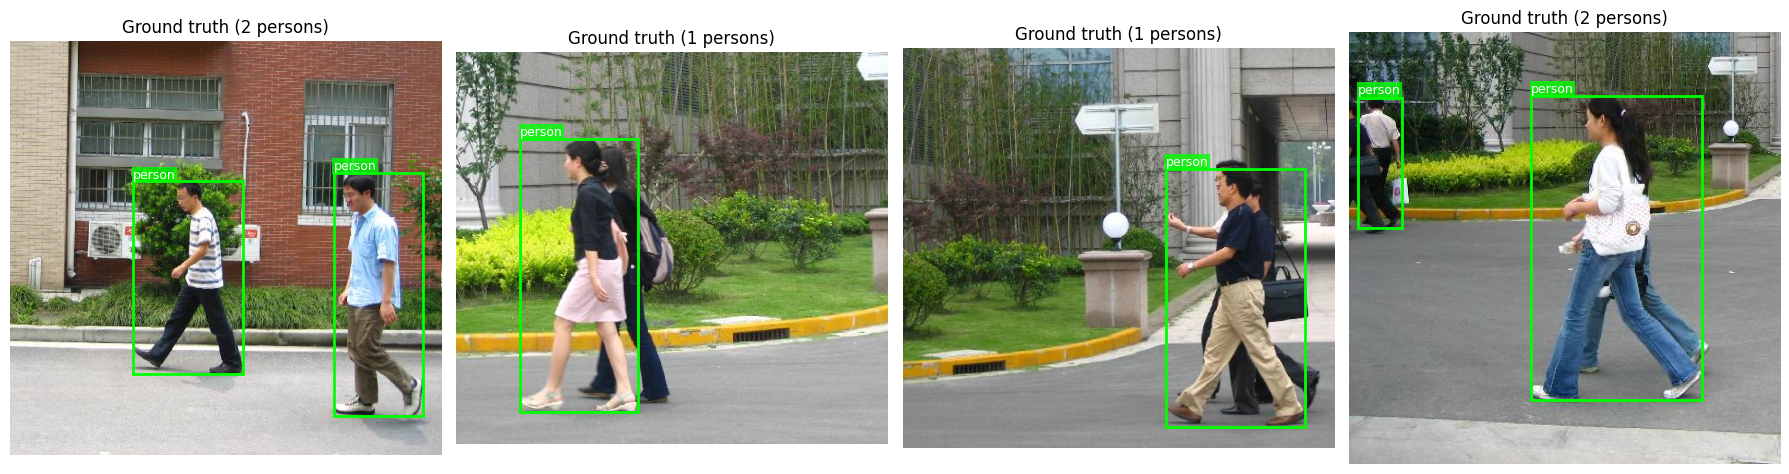

In [6]:
img, target = full_test[0]
print("Image tensor shape :", tuple(img.shape))
print("Target keys        :", list(target.keys()))
print("boxes  [N,4] float :", target["boxes"])
print("labels [N]   int64 :", target["labels"])

def draw_boxes(ax, boxes, color, texts=None):
    for i, (x1, y1, x2, y2) in enumerate(boxes.tolist()):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
        if texts is not None:
            ax.text(x1, max(y1 - 4, 0), texts[i], color="white", fontsize=9,
                    bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, i in zip(axes, [0, 1, 2, 3]):
    im, tg = full_test[i]
    ax.imshow(im.permute(1, 2, 0))
    draw_boxes(ax, tg["boxes"], "lime", [CLASS_NAMES[l] for l in tg["labels"]])
    ax.set_title(f"Ground truth ({len(tg['boxes'])} persons)"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Model: backbone + RPN + detection head

| Component | What we use |
|---|---|
| Backbone | ResNet-50 with a Feature Pyramid Network (FPN), COCO-pretrained |
| RPN | Anchors at 5 FPN levels, 3 aspect ratios each; predicts objectness + box offsets, NMS on proposals |
| Detection head | RoIAlign (7x7) -> two FC layers -> classifier + box regressor |

Only the final predictor is replaced, so it outputs 2 classes (background, person) instead of 91 COCO classes.

In [7]:
def build_model(num_classes=NUM_CLASSES):
    # smaller image size than the default (800) keeps memory/time low and still works well here
    model = fasterrcnn_resnet50_fpn(
        weights="DEFAULT",              # COCO-pretrained weights (transfer learning)
        min_size=640, max_size=1000,    # image resize range
        rpn_post_nms_top_n_train=1000,  # proposals kept after NMS during training
        rpn_post_nms_top_n_test=500,    # proposals kept after NMS during testing
        box_detections_per_img=50,
    )
    # swap the detection head's final layer for our number of classes
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

model = build_model().to(device)

print("Backbone       :", type(model.backbone).__name__, "(ResNet-50 + FPN)")
print("Anchor sizes   :", model.rpn.anchor_generator.sizes)
print("Aspect ratios  :", model.rpn.anchor_generator.aspect_ratios[0])
print("RoI pooler     :", type(model.roi_heads.box_roi_pool).__name__)
print("Detection head :", model.roi_heads.box_predictor)
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters     : {total/1e6:.1f}M total, {trainable/1e6:.1f}M trainable")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 173MB/s]


Backbone       : BackboneWithFPN (ResNet-50 + FPN)
Anchor sizes   : ((32,), (64,), (128,), (256,), (512,))
Aspect ratios  : (0.5, 1.0, 2.0)
RoI pooler     : MultiScaleRoIAlign
Detection head : FastRCNNPredictor(
  (cls_score): Linear(in_features=1024, out_features=2, bias=True)
  (bbox_pred): Linear(in_features=1024, out_features=8, bias=True)
)
Parameters     : 41.3M total, 41.1M trainable


## 4. Training

Hyperparameters:
- Optimizer: SGD (momentum 0.9, weight decay 5e-4)
- Learning rate: 0.005, divided by 10 every 4 epochs (StepLR)
- Batch size: 4, Epochs: 10

In [8]:
def train_model(model, epochs=10, lr=0.005, step_size=4):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=0.1)

    history = {"total": [], "loss_classifier": [], "loss_box_reg": [],
               "loss_objectness": [], "loss_rpn_box_reg": []}

    for epoch in range(epochs):
        model.train()
        start = time.time()
        running = {k: 0.0 for k in history}

        for images, targets in train_loader:
            images = [im.to(device) for im in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(images, targets)      # in train mode the model returns losses
            loss = sum(loss_dict.values())

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running["total"] += loss.item()
            for k, v in loss_dict.items():
                running[k] += v.item()

        scheduler.step()
        n = len(train_loader)
        for k in history:
            history[k].append(running[k] / n)
        print(f"Epoch {epoch+1:2d}/{epochs} | loss {history['total'][-1]:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.5f} | {time.time()-start:.0f}s")
    return history

history = train_model(model, epochs=10, lr=0.005, step_size=4)

Epoch  1/10 | loss 0.3418 | lr 0.00500 | 27s
Epoch  2/10 | loss 0.1484 | lr 0.00500 | 23s
Epoch  3/10 | loss 0.1164 | lr 0.00500 | 24s
Epoch  4/10 | loss 0.1022 | lr 0.00050 | 25s
Epoch  5/10 | loss 0.0853 | lr 0.00050 | 26s
Epoch  6/10 | loss 0.0809 | lr 0.00050 | 25s
Epoch  7/10 | loss 0.0778 | lr 0.00050 | 25s
Epoch  8/10 | loss 0.0753 | lr 0.00005 | 26s
Epoch  9/10 | loss 0.0748 | lr 0.00005 | 26s
Epoch 10/10 | loss 0.0743 | lr 0.00005 | 26s


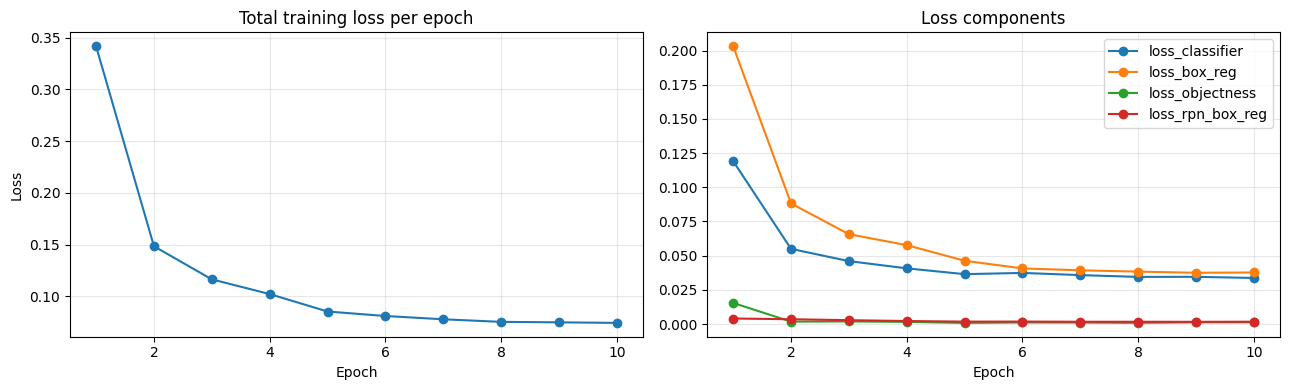

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, len(history["total"]) + 1), history["total"], marker="o")
ax[0].set_title("Total training loss per epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].grid(alpha=0.3)

for k in ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]:
    ax[1].plot(range(1, len(history[k]) + 1), history[k], marker="o", label=k)
ax[1].set_title("Loss components"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Evaluation (mAP on held-out test images)

mAP is computed with `torchmetrics`: `map` = mean AP over IoU 0.50 to 0.95 (COCO style), `map_50` = AP at IoU 0.5, `map_75` = AP at IoU 0.75.

In [10]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    metric = MeanAveragePrecision(iou_type="bbox")
    for images, targets in loader:
        outputs = model([im.to(device) for im in images])
        preds = [{k: v.cpu() for k, v in o.items()} for o in outputs]
        metric.update(preds, [{k: v.cpu() for k, v in t.items()} for t in targets])
    res = metric.compute()
    keys = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large", "mar_100"]
    return {k: round(res[k].item(), 4) for k in keys}

results = evaluate(model, test_loader)
for k, v in results.items():
    print(f"{k:11s}: {v}")

map        : 0.8332
map_50     : 0.9931
map_75     : 0.9343
map_small  : 0.6252
map_medium : 0.7132
map_large  : 0.8497
mar_100    : 0.8628


## 6. Visualise ground truth vs predictions

Left = ground truth (green), right = model prediction (red, with confidence). Only predictions with confidence above 0.7 are drawn.

Image 1: GT=5, predicted=5, best IoU per GT box = [0.94, 0.93, 0.86, 0.96, 0.9]
Image 2: GT=3, predicted=3, best IoU per GT box = [0.97, 0.94, 0.92]
Image 3: GT=6, predicted=6, best IoU per GT box = [0.84, 0.82, 0.92, 0.93, 0.87, 0.71]
Image 4: GT=1, predicted=1, best IoU per GT box = [0.95]
Image 5: GT=5, predicted=4, best IoU per GT box = [0.97, 0.9, 0.89, 0.94, 0.11]
Image 6: GT=2, predicted=2, best IoU per GT box = [0.94, 0.97]


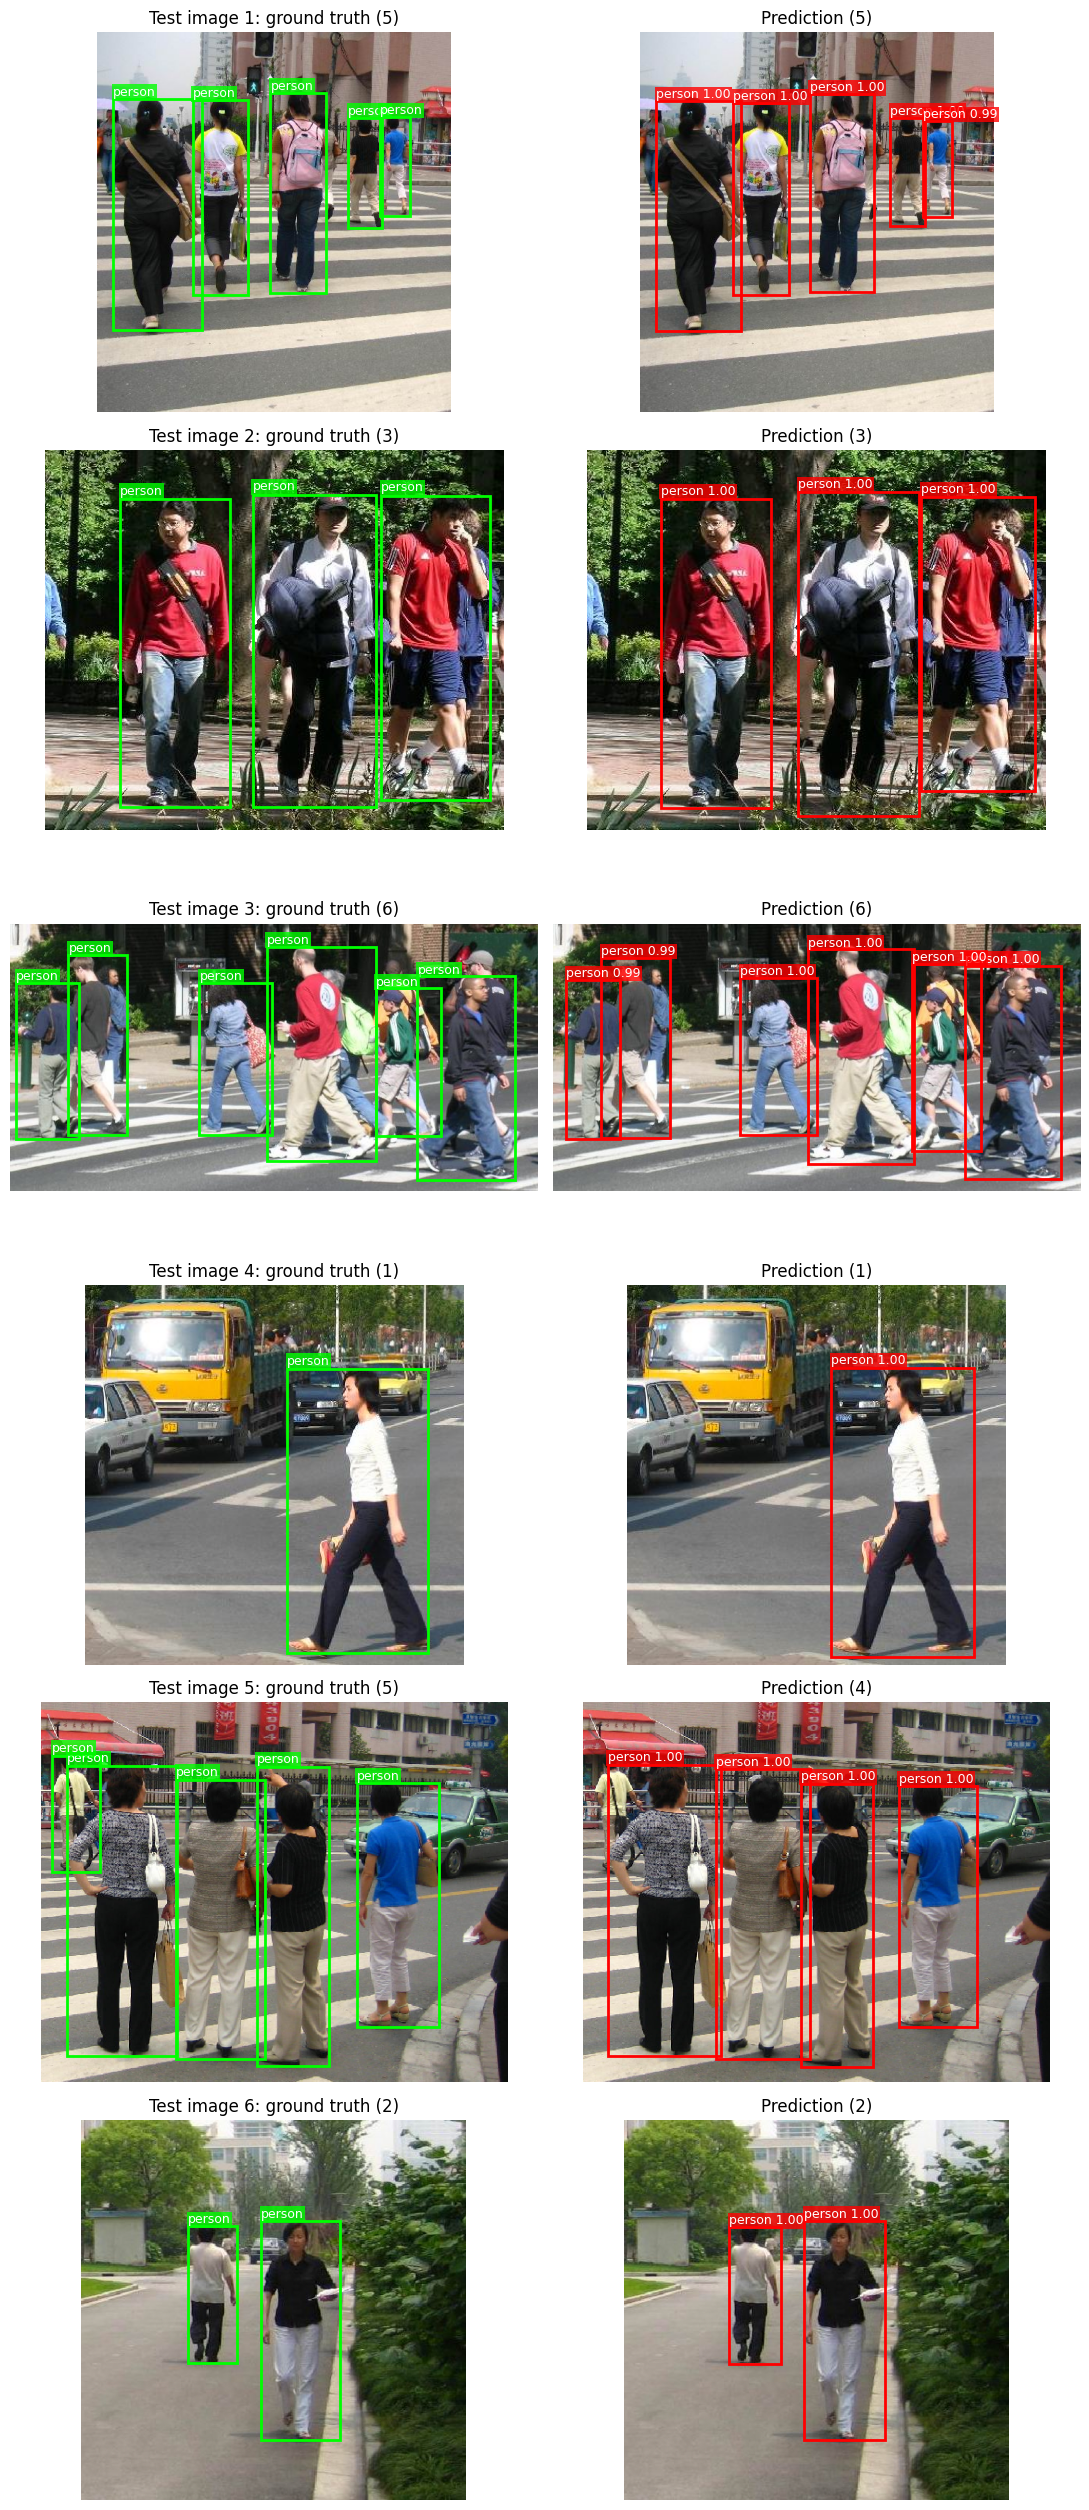


Mean best-IoU over these 22 ground-truth boxes: 0.871


In [11]:
SCORE_THRESH = 0.7

@torch.no_grad()
def predict(model, img, thresh=SCORE_THRESH):
    model.eval()
    out = model([img.to(device)])[0]
    keep = out["scores"] >= thresh
    return {k: v[keep].cpu() for k, v in out.items()}

n_show = 6
fig, axes = plt.subplots(n_show, 2, figsize=(11, 4.2 * n_show))
ious_all = []
for row in range(n_show):
    img, gt = test_ds[row]
    pred = predict(model, img)

    axes[row, 0].imshow(img.permute(1, 2, 0))
    draw_boxes(axes[row, 0], gt["boxes"], "lime", ["person"] * len(gt["boxes"]))
    axes[row, 0].set_title(f"Test image {row+1}: ground truth ({len(gt['boxes'])})")

    axes[row, 1].imshow(img.permute(1, 2, 0))
    texts = [f"{CLASS_NAMES[l]} {s:.2f}" for l, s in zip(pred["labels"].tolist(), pred["scores"].tolist())]
    draw_boxes(axes[row, 1], pred["boxes"], "red", texts)
    axes[row, 1].set_title(f"Prediction ({len(pred['boxes'])})")
    axes[row, 0].axis("off"); axes[row, 1].axis("off")

    # best IoU of each ground-truth box with any prediction (localisation quality)
    if len(pred["boxes"]) > 0:
        best = box_iou(gt["boxes"], pred["boxes"]).max(dim=1).values
        ious_all.extend(best.tolist())
        print(f"Image {row+1}: GT={len(gt['boxes'])}, predicted={len(pred['boxes'])}, "
              f"best IoU per GT box = {[round(x, 2) for x in best.tolist()]}")
    else:
        ious_all.extend([0.0] * len(gt["boxes"]))
        print(f"Image {row+1}: GT={len(gt['boxes'])}, predicted=0")
plt.tight_layout(); plt.show()
print(f"\nMean best-IoU over these {len(ious_all)} ground-truth boxes: {np.mean(ious_all):.3f}")

## 7. Optional: compare another configuration

The practical asks to compare runs instead of reporting only one. Set `RUN_EXPERIMENT = True` to train a second model with a lower learning rate and compare it with the first (takes a few more minutes).

In [12]:
RUN_EXPERIMENT = False

if RUN_EXPERIMENT:
    model2 = build_model().to(device)
    history2 = train_model(model2, epochs=10, lr=0.001, step_size=4)
    results2 = evaluate(model2, test_loader)
    print("\nRun 1 (lr=0.005):", results)
    print("Run 2 (lr=0.001):", results2)

## 8. Save the model

In [13]:
torch.save(model.state_dict(), "fasterrcnn_pennfudan.pth")
print("Saved fasterrcnn_pennfudan.pth")

Saved fasterrcnn_pennfudan.pth


## 9. Experiment summary (fill in after running)

| Item | Value |
|---|---|
| Dataset | Penn-Fudan Pedestrian (120 train / 50 test) |
| Classes | background, person |
| Annotation format | image + target dict: `boxes` [N,4] (xmin, ymin, xmax, ymax), `labels` [N] |
| Model | Faster R-CNN, ResNet-50-FPN, COCO-pretrained |
| Device | (Colab GPU / CPU) |
| Optimizer | SGD, lr 0.005, momentum 0.9, weight decay 5e-4, StepLR (step 4, gamma 0.1) |
| Batch size / Epochs | 4 / 10 |
| mAP / mAP@0.5 / mAP@0.75 | (copy from section 5) |

**Observations:** (loss trend, correct detections, localisation errors such as loose boxes, missed or merged people in crowds, false positives)

**Conclusion:** (2 to 3 lines)